# Bias vs variance with trees — the figure in section 1 of the README

This notebook builds `../images/bias_variance_trees.png`, the three-panel picture used in
[`../README.md`](../README.md) (sections 1 and 3).

**The experiment.** Pretend we can collect many training sets from the same source. We draw
15 of them, each with 60 noisy points from the same pattern, and train the same kind of model on
each one. Then we plot all 15 fitted models on top of each other:

* if the 15 lines sit **in the wrong place** together → **bias**;
* if the 15 lines are **spread out** → **variance**.

Three kinds of model are compared: a stump (depth-1 tree), a fully grown tree, and the average of
100 fully grown trees trained on bootstrap samples (bagging).

In [1]:
from functools import cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

SEED = 0
N_POINTS = 60          # rows in each training set
NOISE_SD = 0.4        # standard deviation of the Gaussian noise added to y
N_TRAINING_SETS = 15  # how many independent training sets (= blue lines per panel)
N_BAGGED_TREES = 100  # trees averaged inside the bagging model
X_MIN, X_MAX = 0.0, 5.0

OUTPUT_PATH = Path("../images/bias_variance_trees.png")

## 1. The source of the data

The true pattern is $f(x) = \sin(2x) + 0.3x$: a wave on a gentle upward trend. A training set is
60 values of $x$ drawn uniformly from $[0, 5]$, with $y = f(x) + \varepsilon$ and
$\varepsilon \sim \mathcal{N}(0, 0.4^2)$.

In [2]:
def true_pattern(x):
    return np.sin(2 * x) + 0.3 * x


def draw_training_set(rng):
    x = rng.uniform(X_MIN, X_MAX, N_POINTS)
    y = true_pattern(x) + rng.normal(0, NOISE_SD, N_POINTS)
    return x.reshape(-1, 1), y


rng = np.random.default_rng(SEED)
training_sets = [draw_training_set(rng) for _ in range(N_TRAINING_SETS)]

x_grid = np.linspace(X_MIN, X_MAX, 500)
truth = true_pattern(x_grid)
print(f"{len(training_sets)} training sets of {N_POINTS} points each")

15 training sets of 60 points each


## 2. The three models

Each entry makes a fresh, untrained model. `seed` only matters for bagging (which bootstrap rows
each tree sees); it is set per training set so the whole notebook is reproducible.

In [3]:
MODELS = {
    "stump": lambda seed: DecisionTreeRegressor(max_depth=1),
    "deep tree": lambda seed: DecisionTreeRegressor(random_state=seed),
    "bagging": lambda seed: BaggingRegressor(
        DecisionTreeRegressor(), n_estimators=N_BAGGED_TREES, random_state=seed
    ),
}

PANEL_TITLES = {
    "stump": "stump (depth 1): HIGH bias, low variance",
    "deep tree": "deep tree: low bias, HIGH variance",
    "bagging": f"average of {N_BAGGED_TREES} deep trees (bagging):\nlow bias, lower variance",
}

## 3. Train every model on every training set

`predictions[name]` has shape `(15, 500)`: one row per training set, one column per point of the
plotting grid.

In [4]:
def predict_on_grid(make_model, training_sets, grid):
    return np.array([
        make_model(seed).fit(X, y).predict(grid.reshape(-1, 1))
        for seed, (X, y) in enumerate(training_sets)
    ])


predictions = {name: predict_on_grid(make, training_sets, x_grid) for name, make in MODELS.items()}
{name: preds.shape for name, preds in predictions.items()}

{'stump': (15, 500), 'deep tree': (15, 500), 'bagging': (15, 500)}

## 4. The numbers behind the picture

Using the decomposition from section 3 of the README, averaged over the grid:

* **bias²** = squared distance between the *average* of the 15 fits and the true pattern;
* **variance** = spread of the 15 fits around their own average.

With only 15 training sets these are rough estimates, but the ordering is what the figure shows.

In [5]:
def bias_squared_and_variance(preds):
    average_fit = preds.mean(axis=0)
    bias_squared = np.mean((average_fit - truth) ** 2)
    variance = np.mean(preds.var(axis=0))
    return bias_squared, variance


print(f"{'model':<10} {'bias^2':>8} {'variance':>9}")
for name, preds in predictions.items():
    bias_squared, variance = bias_squared_and_variance(preds)
    print(f"{name:<10} {bias_squared:>8.3f} {variance:>9.3f}")

model        bias^2  variance
stump         0.216     0.027
deep tree     0.009     0.161
bagging       0.005     0.078


## 5. Draw and save the figure

Blue: the 15 individual fits. Orange: their average. Black dashed: the true pattern.

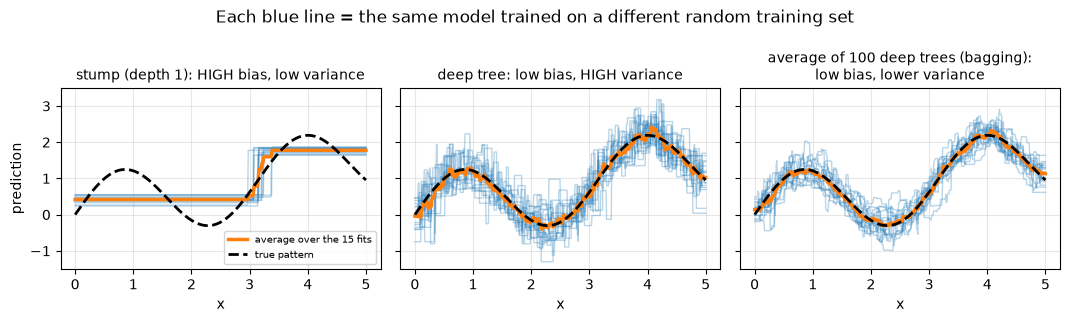

saved ../images/bias_variance_trees.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.24), sharey=True)

for ax, (name, preds) in zip(axes, predictions.items()):
    for single_fit in preds:
        ax.plot(x_grid, single_fit, color="tab:blue", alpha=0.3, lw=1)
    ax.plot(x_grid, preds.mean(axis=0), color="tab:orange", lw=2.5,
            label=f"average over the {N_TRAINING_SETS} fits")
    ax.plot(x_grid, truth, "k--", lw=2, label="true pattern")
    ax.set_title(PANEL_TITLES[name], fontsize=10)
    ax.set_xlabel("x")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("prediction")
axes[0].set_ylim(-1.5, 3.5)
axes[0].legend(loc="lower right", fontsize=7)
fig.suptitle("Each blue line = the same model trained on a different random training set")
fig.tight_layout()

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_PATH, dpi=100)
plt.show()
print(f"saved {OUTPUT_PATH}")

## 6. What to read off the figure

* **Stump.** The 15 lines nearly coincide (low variance) but every one is a single step that cannot
  follow the wave (high bias).
* **Deep tree.** The average (orange) follows the wave (low bias), but each fit is jagged and
  different from the others: it memorised its own sample's noise (high variance).
* **Bagging.** The average still follows the wave, and the individual lines are much calmer:
  averaging 100 trees cancelled part of the noise-chasing. Same low bias, lower variance — the idea
  developed in [`../02-bagging/`](../02-bagging/README.md).

## 7. Beyond the training range: no extrapolation

Every training set covered only $x \in [0, 5]$. What do the same models predict a little further out, where
the true pattern keeps waving upwards? We refit them on the **same 15 training sets** and predict on
$[0, 7.5]$. The grey band is the region no model has seen.

A tree answers "which leaf does this point fall in?". Every $x$ above the largest training value lands in
the **last leaf**, so the prediction stops changing there — for a stump, a deep tree, and an average of
100 deep trees alike. This is [disadvantage 4](../README.md#disadvantage-4) in the README.

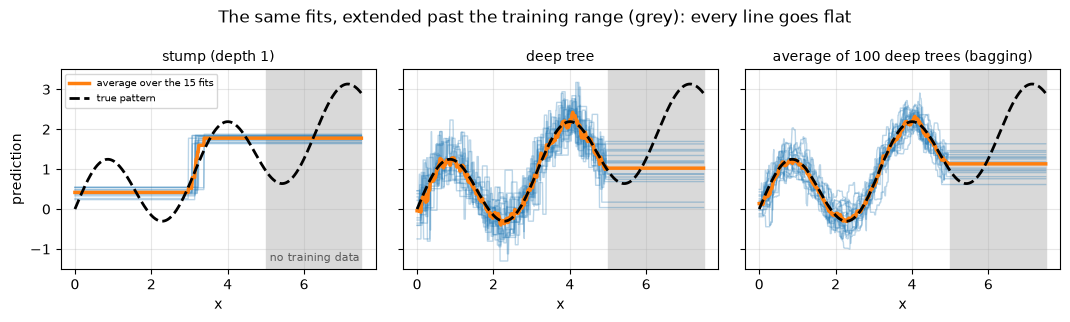

In [7]:
X_EDGE, X_FAR = X_MAX, 7.5
x_wide = np.linspace(X_MIN, X_FAR, 750)
truth_wide = true_pattern(x_wide)
beyond = x_wide > X_EDGE

wide_predictions = {name: predict_on_grid(make, training_sets, x_wide) for name, make in MODELS.items()}

fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.24), sharey=True)
for ax, (name, preds) in zip(axes, wide_predictions.items()):
    ax.axvspan(X_EDGE, X_FAR, color="0.85", zorder=0)
    for single_fit in preds:
        ax.plot(x_wide, single_fit, color="tab:blue", alpha=0.3, lw=1)
    ax.plot(x_wide, preds.mean(axis=0), color="tab:orange", lw=2.5,
            label=f"average over the {N_TRAINING_SETS} fits")
    ax.plot(x_wide, truth_wide, "k--", lw=2, label="true pattern")
    ax.set_title(PANEL_TITLES[name].split(":")[0], fontsize=10)
    ax.set_xlabel("x")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("prediction")
axes[0].set_ylim(-1.5, 3.5)
axes[0].text(X_EDGE + 0.1, -1.3, "no training data", fontsize=8, color="0.35")
axes[0].legend(loc="upper left", fontsize=7)
fig.suptitle("The same fits, extended past the training range (grey): every line goes flat")
fig.tight_layout()
plt.show()

The numbers behind the flat lines. For each model: the average of the 15 fits at $x = 5$ (the edge), $6$
and $7$ against the truth, and the **largest change of any single fit** anywhere past the edge.

In [8]:
def value_at(x_value, curve):
    return np.interp(x_value, x_wide, curve)


print(f"{'model':<10} {'avg@5':>6} {'avg@6':>6} {'avg@7':>6}   {'max change past x=5':>19}")
for name, preds in wide_predictions.items():
    average_fit = preds.mean(axis=0)
    edge_values = preds[:, ~beyond][:, -1:]                 # each fit's value at the last grid point <= 5
    max_change = np.abs(preds[:, beyond] - edge_values).max()
    print(f"{name:<10} {value_at(5, average_fit):6.2f} {value_at(6, average_fit):6.2f} "
          f"{value_at(7, average_fit):6.2f}   {max_change:19.3f}")
print(f"{'truth':<10} {true_pattern(5):6.2f} {true_pattern(6):6.2f} {true_pattern(7):6.2f}")

model       avg@5  avg@6  avg@7   max change past x=5
stump        1.78   1.78   1.78                 0.000
deep tree    1.02   1.02   1.02                 0.000
bagging      1.13   1.13   1.13                 0.000
truth        0.96   1.26   3.09


## 8. What to read off the extrapolation figure

* **Every line goes flat at the edge** — all 15 fits of all three models. The largest change of any fit past
  $x = 5$ is exactly 0: past its last split a tree has nothing left to ask.
* **Bagging does not help.** The average of 100 flat lines is a flat line. Averaging cancels *noise*; it
  cannot invent a shape the members do not have outside the data.
* **Low bias inside the range, growing bias outside it.** The deep tree and the bagged trees follow the wave
  up to $x = 5$ (sections 4–6), but from there the gap to the truth is whatever the wave does next — here the
  gap reaches 2.07 (deep tree) and 1.96 (bagging) by $x = 7$, against 1.31 for the stump.
* **The spread does not shrink either.** Past the edge each fit repeats its own last leaf, so the blue lines
  keep the scatter they had at $x = 5$ — narrow for the stump, wide for the deep tree.
* **What helps instead:** members that carry a trend (a linear model, or trees fitted to what is left after
  removing a trend). The README's [section 13.1](../README.md#131-extrapolation-with-members-that-are-not-trees-disadvantage-4)
  measures this, including bagged and boosted neural networks.

## 9. How few trees are enough? A binary search on `n_estimators`

Section 4 bagged **100** deep trees. In an averaging ensemble more trees never make the predictions worse, they
only cost time — but past some point they stop making them better. How far below 100 can a random forest go
and still predict about as well?

* **"Good enough"** = an error at most `TOLERANCE` (5 %) above the error of the 100-tree forest.
* **The error** = RMSE against the true pattern on $[0, 5]$, **averaged over the 15 training sets** of section 1,
  so that one lucky or unlucky sample does not decide the answer. (We can measure against the truth because we
  made the data; with real data use the out-of-bag error or a validation set instead.)
* **Binary search** works because the question "is $n$ trees good enough?" flips only once: *no* for small $n$,
  *yes* from some $n$ on. Each probe halves the range of candidates, so 1–100 needs about 7 probes instead of
  100. The search keeps two numbers: `high`, a forest size known to be good enough, and `low`, below which
  nothing is.

With one feature, a random forest's "random subset of features at every split" has nothing to choose from, so
here a random forest *is* bagging of deep trees — the right-hand panel of section 1's figure.

In [9]:
TOLERANCE = 0.05                                                  # <- try changing this
N_MAX = 100


@cache
def forest_rmse(n_trees):
    """RMSE against the true pattern on the grid, averaged over the 15 training sets."""
    errors = [
        np.sqrt(np.mean((RandomForestRegressor(n_estimators=n_trees, random_state=seed)
                         .fit(X, y).predict(x_grid.reshape(-1, 1)) - truth) ** 2))
        for seed, (X, y) in enumerate(training_sets)
    ]
    return float(np.mean(errors))


def smallest_good_enough(rmse_of, n_max, tolerance):
    """Binary search for the smallest n in [1, n_max] with rmse_of(n) <= (1 + tolerance) * rmse_of(n_max)."""
    target = (1 + tolerance) * rmse_of(n_max)
    low, high = 1, n_max                       # high is good enough; every n below low is not
    probes = []
    while low < high:
        mid = (low + high) // 2
        good = rmse_of(mid) <= target
        probes.append((low, high, mid, rmse_of(mid), good))
        if good:
            high = mid                         # mid works: the answer is mid or smaller
        else:
            low = mid + 1                      # mid fails: the answer is larger than mid
    return high, target, probes


best_n, target, probes = smallest_good_enough(forest_rmse, N_MAX, TOLERANCE)

print(f"100 trees: RMSE {forest_rmse(N_MAX):.4f};  good enough = RMSE <= {target:.4f} (+{TOLERANCE:.0%})\n")
print(f"{'probe':>5} {'search range':>14} {'try n':>6} {'RMSE':>8}  verdict")
for step, (low, high, mid, rmse, good) in enumerate(probes, start=1):
    print(f"{step:5d} {f'[{low}, {high}]':>14} {mid:6d} {rmse:8.4f}  {'good enough' if good else 'too few trees'}")
print(f"\nsmallest good-enough forest: {best_n} trees (RMSE {forest_rmse(best_n):.4f}), "
      f"found with {len(probes)} probes")

100 trees: RMSE 0.2860;  good enough = RMSE <= 0.3003 (+5%)

probe   search range  try n     RMSE  verdict
    1       [1, 100]     50   0.2872  good enough
    2        [1, 50]     25   0.2918  good enough
    3        [1, 25]     13   0.2979  good enough
    4        [1, 13]      7   0.3048  too few trees
    5        [8, 13]     10   0.3008  too few trees
    6       [11, 13]     12   0.2955  good enough
    7       [11, 12]     11   0.2972  good enough

smallest good-enough forest: 11 trees (RMSE 0.2972), found with 7 probes


The answer depends on how strict "good enough" is. The same search for several tolerances (probes already
computed are remembered by `@cache`, so later searches are cheaper):

In [10]:
print(f"{'tolerance':>9} {'smallest n':>11} {'its RMSE':>9} {'probes':>7}")
for tolerance in [0.01, 0.02, 0.05, 0.07, 0.10, 0.20]:
    n, _, tolerance_probes = smallest_good_enough(forest_rmse, N_MAX, tolerance)
    print(f"{tolerance:9.0%} {n:11d} {forest_rmse(n):9.4f} {len(tolerance_probes):7d}")

tolerance  smallest n  its RMSE  probes


       1%          41    0.2886       6


       2%          27    0.2907       7
       5%          11    0.2972       7
       7%           7    0.3048       6
      10%           6    0.3084       7
      20%           3    0.3374       7


**Checking the search.** Binary search is only right if the answer really flips once. To check, we compute the
error for *every* forest size from 1 to 100 (about 100 times the work of the search) and compare.

binary search answer                         : 11
first size in the sweep under the target       : 11
first size from which every larger one is under: 11

share of the whole 1 -> 100 improvement already won with n trees:
   1 trees: RMSE 0.4134     0.0%
   2 trees: RMSE 0.3512    48.8%
   3 trees: RMSE 0.3374    59.6%
   5 trees: RMSE 0.3161    76.4%
   7 trees: RMSE 0.3048    85.2%
  11 trees: RMSE 0.2972    91.2%
  25 trees: RMSE 0.2918    95.4%
  50 trees: RMSE 0.2872    99.0%
 100 trees: RMSE 0.2860   100.0%


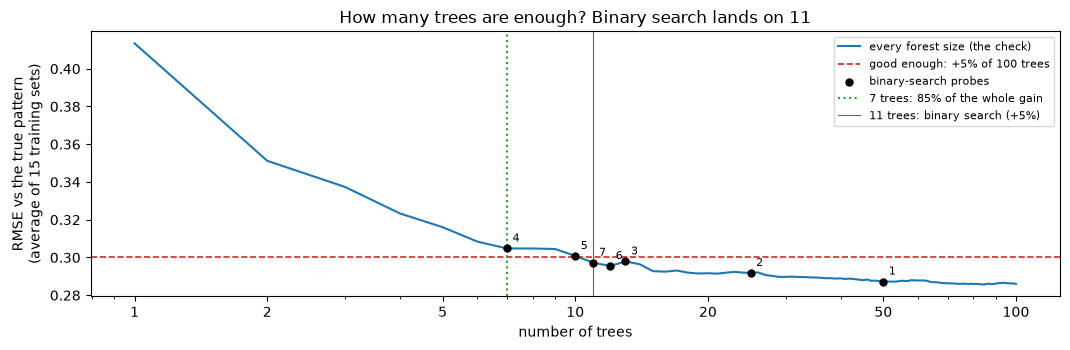

In [11]:
sizes = np.arange(1, N_MAX + 1)
sweep = np.array([forest_rmse(int(n)) for n in sizes])

under = sweep <= target
first_under = int(sizes[under][0])
stays_under = int(sizes[~under][-1] + 1) if (~under).any() else 1   # from here on, every size is good enough
print(f"binary search answer                         : {best_n}")
print(f"first size in the sweep under the target       : {first_under}")
print(f"first size from which every larger one is under: {stays_under}")

KNEE = 7
gain = sweep[0] - sweep[-1]                    # the whole improvement from 1 tree to 100
print(f"\nshare of the whole 1 -> {N_MAX} improvement already won with n trees:")
for n in [1, 2, 3, 5, KNEE, best_n, 25, 50, N_MAX]:
    print(f"{n:4d} trees: RMSE {forest_rmse(n):.4f}   {(sweep[0] - forest_rmse(n)) / gain:6.1%}")

fig, ax = plt.subplots(figsize=(10.8, 3.6))
ax.plot(sizes, sweep, color="tab:blue", lw=1.5, label="every forest size (the check)")
ax.axhline(target, color="tab:red", ls="--", lw=1.2, label=f"good enough: +{TOLERANCE:.0%} of 100 trees")
ax.scatter([p[2] for p in probes], [p[3] for p in probes], color="black", zorder=3, s=25,
           label="binary-search probes")
for step, (_, _, mid, rmse, _) in enumerate(probes, start=1):
    ax.annotate(str(step), (mid, rmse), textcoords="offset points", xytext=(4, 5), fontsize=8)
ax.axvline(KNEE, color="tab:green", ls=":", lw=1.5,
           label=f"{KNEE} trees: {(sweep[0] - forest_rmse(KNEE)) / gain:.0%} of the whole gain")
ax.axvline(best_n, color="0.4", lw=0.8, label=f"{best_n} trees: binary search (+{TOLERANCE:.0%})")
ax.set(xscale="log", xlabel="number of trees", ylabel="RMSE vs the true pattern\n(average of 15 training sets)",
       title=f"How many trees are enough? Binary search lands on {best_n}")
ticks = [1, 2, 5, 10, 20, 50, 100]
ax.set_xticks(ticks, labels=[str(t) for t in ticks])
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * **11 trees are enough** for a 5 % tolerance: RMSE 0.2972 against 0.2860 for 100 trees, with a forest a ninth
>   of the size (so about nine times faster to train and to predict). The search needed 7 probes — 50, 25, 13, 7,
>   10, 12, 11 — each halving the range of candidates.
> * **Value 7 as well — that is where the battle is won.** Seven trees already win **85 %** of the whole
>   improvement from 1 tree to 100 (RMSE 0.4134 → 0.3048, against 0.2860 for 100): 2 trees win 49 %, 3 trees
>   60 %, 5 trees 76 %, 7 trees 85 %. After that it is a battle for scraps: 4 more trees buy the next 6 % (11 trees,
>   91 %), and 93 more buy the last 15 %. The plot shows it — the curve falls steeply up to the green dotted line
>   at 7 and is nearly flat after it. The 5 % rule lands on 11 only because its red line sits just below 7's error
>   (0.3003 vs 0.3048): a 7 % tolerance already picks 7.
> * **The answer is set by the tolerance, not by the data alone:** 41 trees for 1 %, 27 for 2 %, 11 for 5 %, 7 for
>   7 %, 6 for 10 %, 3 for 20 %. Almost all of the gain comes from the first ten or so trees: one tree is above 0.40 (left end
>   of the plot), ten are at 0.30, a hundred at 0.286.
> * **Why it levels off:** section 3's formula. The variance of an average of $B$ trees is
>   $\rho\sigma^2 + (1 - \rho)\sigma^2 / B$; the second part shrinks like $1/B$, so going from 10 to 100 trees removes
>   90 % of a part that is already small, and the floor $\rho\sigma^2$ and the bias do not move at all.
> * **The check agrees** (11 in all three lines). The curve is not perfectly smooth — 12 trees (0.2955) beat 11
>   (0.2972) and 13 (0.2979), depending on which trees happen to be added — but it crosses the red line only once,
>   which is all binary search needs. If the curve wobbled across the line, the search could stop at a size whose
>   neighbours fail; that is why the full sweep is worth running once.
> * **Caveat:** this is 60 points and one feature. Larger or noisier data, many features, or classification
>   probabilities usually need more trees; on real data, run the same search on the out-of-bag error.

## 10. A timeline: one forest, tree by tree

Section 9 measured how the error falls as trees are added. Here we watch it happen on one training set (the
first of the 15): one random forest of 100 trees, shown after its first 1, 2, …, 7 trees and after all 100.

* each **thin blue line** is one tree — a deep tree trained on its own bootstrap sample;
* the **orange line** is the forest so far — the average of those trees;
* the **black dashed line** is the true pattern, the grey dots the 60 training points.

The first $n$ trees of a 100-tree forest are exactly the forest you get by asking for $n$ trees with the same
`random_state` (checked below), so these are the same forests section 9 measured.

first 7 trees of the 100-tree forest == a 7-tree forest: True


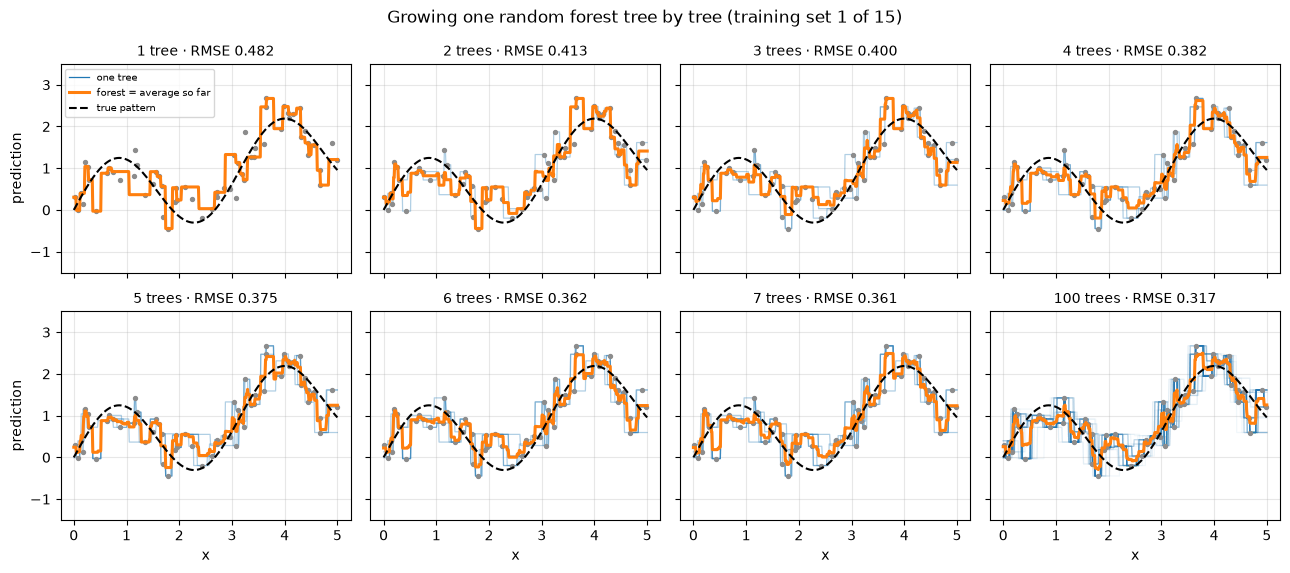

In [12]:
X0, y0 = training_sets[0]
forest = RandomForestRegressor(n_estimators=N_MAX, random_state=0).fit(X0, y0)
tree_curves = np.array([tree.predict(x_grid.reshape(-1, 1)) for tree in forest.estimators_])   # (100, 500)

seven_from_scratch = RandomForestRegressor(n_estimators=7, random_state=0).fit(X0, y0).predict(x_grid.reshape(-1, 1))
print("first 7 trees of the 100-tree forest == a 7-tree forest:",
      np.allclose(tree_curves[:7].mean(axis=0), seven_from_scratch))

TIMELINE = [1, 2, 3, 4, 5, 6, 7, N_MAX]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.8), sharex=True, sharey=True)
for ax, n in zip(axes.flat, TIMELINE):
    forest_curve = tree_curves[:n].mean(axis=0)
    rmse = np.sqrt(np.mean((forest_curve - truth) ** 2))
    for curve in tree_curves[:n]:
        ax.plot(x_grid, curve, color="tab:blue", alpha=0.35 if n <= 7 else 0.06, lw=0.9)
    ax.scatter(X0[:, 0], y0, s=8, color="0.55", zorder=2)
    ax.plot(x_grid, truth, "k--", lw=1.5, zorder=4)
    ax.plot(x_grid, forest_curve, color="tab:orange", lw=2.2, zorder=3)
    ax.set_title(f"{n} tree{'s' if n > 1 else ''} · RMSE {rmse:.3f}", fontsize=10)
    ax.grid(alpha=0.3)

axes[0, 0].set_ylim(-1.5, 3.5)
for ax in axes[1]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("prediction")
axes[0, 0].plot([], [], color="tab:blue", lw=0.9, label="one tree")
axes[0, 0].plot([], [], color="tab:orange", lw=2.2, label="forest = average so far")
axes[0, 0].plot([], [], "k--", lw=1.5, label="true pattern")
axes[0, 0].legend(loc="upper left", fontsize=7)
fig.suptitle("Growing one random forest tree by tree (training set 1 of 15)")
plt.tight_layout(); plt.show()

> **How to read this**
> * **1 tree:** the forest *is* one deep tree — a jagged staircase that runs through almost every training point,
>   noise included (RMSE 0.482).
> * **2–4 trees:** each tree was grown on a different bootstrap sample, so its spikes sit in different places.
>   Averaging cuts the spikes down where the trees disagree (0.413, 0.400, 0.382).
> * **By 7 trees the orange line has nearly its final shape** (0.361): the big spikes are gone and what is left is
>   what most trees agree on. From 7 to 100 trees the line only smooths small steps (0.361 → 0.317).
> * On this one training set, 7 trees win 73 % of the 1 → 100 improvement; averaged over all 15 sets it is 85 %
>   (section 9). A single set is noisier than the average.
> * **What averaging cannot fix:** places where all the trees agree on the wrong value. Around $x \approx 0.5$–$1.3$
>   the forest stays below the true peak at every size, because this sample's points there happen to sit low and
>   every tree sees a subset of the same 60 points. That shared error is the floor $\rho\sigma^2$ of section 3 —
>   more trees do not move it.

## 11. Testing the variance formula, one forest size at a time

Section 3 of the README says the variance of an average of $n$ members is

$$\underbrace{\text{Var}\Big(\tfrac1n\sum_{i=1}^{n} \hat f_i\Big)}_{\text{LHS}} \;=\; \underbrace{\rho\,\sigma^2 + \frac{1-\rho}{n}\,\sigma^2}_{\text{RHS}},$$

which assumes every member has the same variance $\sigma^2$ and every pair the same correlation $\rho$. The cells
below take the forests of section 10's timeline — the first 1, 2, …, 7 trees — and, for each size, print:

1. **every estimator's variance** $\sigma_i^2$, one line per tree;
2. **the pairwise correlation table** $\rho_{ij}$;
3. **the LHS**: the actual variance of the $n$-tree forest's prediction;
4. **the RHS as written**, summed term by term. It takes a single $\sigma^2$ — the mean of the printed variances —
   and a single $\rho$, computed two ways: the plain mean of the printed correlations, and the mean covariance
   between estimators divided by the mean variance;
5. **the RHS without the equal-$\rho$ assumption**, $\frac{1}{n^2}\sum_i\sum_j \rho_{ij}\,\sigma_i\,\sigma_j$.

Everything is measured at **one input**, $x = 2.5$, so nothing is averaged over $x$. A variance or a correlation
is a spread *across training sets*: on section 10's single training set each tree's prediction at $x = 2.5$ is
just one number. So we draw **1 000 training sets** from the same source and grow a 7-tree forest on each; the
first $n$ trees of each forest are its $n$-tree forest (checked in section 10).

In [13]:
N_REPEATS = 1000
N_TREES = 7
X_POINT = 2.5                                                     # <- try changing this
rng_repeats = np.random.default_rng(SEED + 1)

tree_at_point = np.empty((N_REPEATS, N_TREES))    # row = training set, column = tree: its prediction at X_POINT
for r in range(N_REPEATS):
    X_r, y_r = draw_training_set(rng_repeats)
    forest_r = RandomForestRegressor(n_estimators=N_TREES, random_state=r).fit(X_r, y_r)
    tree_at_point[r] = [tree.predict([[X_POINT]])[0] for tree in forest_r.estimators_]


def check_formula(n):
    """Print sigma_i^2 per estimator, the rho_ij table, the LHS and both RHS for the forest of the first n trees."""
    predictions = tree_at_point[:, :n]
    variances = predictions.var(axis=0)                           # sigma_i^2, one per estimator
    rho = np.corrcoef(predictions, rowvar=False).reshape(n, n)     # rho_ij
    lhs = predictions.mean(axis=1).var()                          # variance of the n-tree forest's prediction

    for i, variance in enumerate(variances, start=1):
        print(f"estimator {i}, variance = {variance:.5f}")
    if n > 1:
        print("\npairwise correlation rho_ij:")
        print("        " + "".join(f"{'est ' + str(j):>8}" for j in range(1, n + 1)))
        for i in range(n):
            print(f"est {i + 1:<4}" + "".join(f"{rho[i, j]:8.3f}" for j in range(n)))

    print(f"\nLHS  actual variance of the {n}-tree forest's prediction: {lhs:.5f}")
    if n == 1:
        print(f"RHS  one estimator, no pairs: rho*s2 + (1 - rho)*s2/1 = s2 for any rho = {variances[0]:.5f}")
        return
    off_diagonal = rho[~np.eye(n, dtype=bool)]
    rho_bar, sigma2_bar = off_diagonal.mean(), variances.mean()
    term_1, term_2 = rho_bar * sigma2_bar, (1 - rho_bar) * sigma2_bar / n
    rhs_equal = term_1 + term_2
    print(f"RHS  as written, with rho = plain mean of the {off_diagonal.size // 2} pairwise values = {rho_bar:.4f} "
          f"and sigma^2 = mean of the {n} variances = {sigma2_bar:.5f}:")
    print(f"     {rho_bar:.4f} x {sigma2_bar:.5f} + (1 - {rho_bar:.4f}) x {sigma2_bar:.5f} / {n}"
          f" = {term_1:.5f} + {term_2:.5f} = {rhs_equal:.5f}   ({(rhs_equal / lhs - 1):+.1%} vs LHS)")
    cov_bar = np.cov(predictions, rowvar=False, ddof=0)[~np.eye(n, dtype=bool)].mean()
    rho_cov = cov_bar / sigma2_bar
    cov_1, cov_2 = rho_cov * sigma2_bar, (1 - rho_cov) * sigma2_bar / n
    print(f"RHS  as written, with rho = mean covariance / mean variance = {cov_bar:.5f} / {sigma2_bar:.5f} = {rho_cov:.4f}:")
    print(f"     {rho_cov:.4f} x {sigma2_bar:.5f} + (1 - {rho_cov:.4f}) x {sigma2_bar:.5f} / {n}"
          f" = {cov_1:.5f} + {cov_2:.5f} = {cov_1 + cov_2:.5f}   ({((cov_1 + cov_2) / lhs - 1):+.4%} vs LHS)")
    sigma = np.sqrt(variances)
    diagonal_sum = (sigma ** 2).sum()
    pair_sum = (rho * np.outer(sigma, sigma))[~np.eye(n, dtype=bool)].sum()
    rhs_pairs = (diagonal_sum + pair_sum) / n ** 2
    print(f"RHS  without the equal-rho assumption, (1/n^2) * sum_i sum_j rho_ij sigma_i sigma_j:")
    print(f"     (1/{n * n}) x ({diagonal_sum:.5f} + {pair_sum:.5f}) = {rhs_pairs:.5f}   "
          f"({(rhs_pairs / lhs - 1):+.1%} vs LHS)")


print(f"{N_REPEATS} training sets, {N_TREES} trees each; every value below is measured at x = {X_POINT}")

1000 training sets, 7 trees each; every value below is measured at x = 2.5


### 11.1 · `n_estimators = 1`

In [14]:
check_formula(1)

estimator 1, variance = 0.17227

LHS  actual variance of the 1-tree forest's prediction: 0.17227
RHS  one estimator, no pairs: rho*s2 + (1 - rho)*s2/1 = s2 for any rho = 0.17227


### 11.2 · `n_estimators = 2`

In [15]:
check_formula(2)

estimator 1, variance = 0.17227
estimator 2, variance = 0.17171

pairwise correlation rho_ij:
           est 1   est 2
est 1      1.000   0.507
est 2      0.507   1.000

LHS  actual variance of the 2-tree forest's prediction: 0.12961
RHS  as written, with rho = plain mean of the 1 pairwise values = 0.5072 and sigma^2 = mean of the 2 variances = 0.17199:
     0.5072 x 0.17199 + (1 - 0.5072) x 0.17199 / 2 = 0.08723 + 0.04238 = 0.12961   (+0.0% vs LHS)
RHS  as written, with rho = mean covariance / mean variance = 0.08723 / 0.17199 = 0.5072:
     0.5072 x 0.17199 + (1 - 0.5072) x 0.17199 / 2 = 0.08723 + 0.04238 = 0.12961   (-0.0000% vs LHS)
RHS  without the equal-rho assumption, (1/n^2) * sum_i sum_j rho_ij sigma_i sigma_j:
     (1/4) x (0.34397 + 0.17446) = 0.12961   (-0.0% vs LHS)


### 11.3 · `n_estimators = 3`

In [16]:
check_formula(3)

estimator 1, variance = 0.17227
estimator 2, variance = 0.17171
estimator 3, variance = 0.16503

pairwise correlation rho_ij:
           est 1   est 2   est 3
est 1      1.000   0.507   0.487
est 2      0.507   1.000   0.478
est 3      0.487   0.478   1.000

LHS  actual variance of the 3-tree forest's prediction: 0.11207
RHS  as written, with rho = plain mean of the 3 pairwise values = 0.4907 and sigma^2 = mean of the 3 variances = 0.16967:
     0.4907 x 0.16967 + (1 - 0.4907) x 0.16967 / 3 = 0.08326 + 0.02880 = 0.11207   (-0.0% vs LHS)
RHS  as written, with rho = mean covariance / mean variance = 0.08327 / 0.16967 = 0.4908:
     0.4908 x 0.16967 + (1 - 0.4908) x 0.16967 / 3 = 0.08327 + 0.02880 = 0.11207   (-0.0000% vs LHS)
RHS  without the equal-rho assumption, (1/n^2) * sum_i sum_j rho_ij sigma_i sigma_j:
     (1/9) x (0.50901 + 0.49964) = 0.11207   (-0.0% vs LHS)


### 11.4 · `n_estimators = 4`

In [17]:
check_formula(4)

estimator 1, variance = 0.17227
estimator 2, variance = 0.17171
estimator 3, variance = 0.16503
estimator 4, variance = 0.15105

pairwise correlation rho_ij:
           est 1   est 2   est 3   est 4
est 1      1.000   0.507   0.487   0.487
est 2      0.507   1.000   0.478   0.425
est 3      0.487   0.478   1.000   0.404
est 4      0.487   0.425   0.404   1.000

LHS  actual variance of the 4-tree forest's prediction: 0.09884
RHS  as written, with rho = plain mean of the 6 pairwise values = 0.4648 and sigma^2 = mean of the 4 variances = 0.16501:
     0.4648 x 0.16501 + (1 - 0.4648) x 0.16501 / 4 = 0.07670 + 0.02208 = 0.09878   (-0.1% vs LHS)
RHS  as written, with rho = mean covariance / mean variance = 0.07679 / 0.16501 = 0.4653:
     0.4653 x 0.16501 + (1 - 0.4653) x 0.16501 / 4 = 0.07679 + 0.02206 = 0.09884   (-0.0000% vs LHS)
RHS  without the equal-rho assumption, (1/n^2) * sum_i sum_j rho_ij sigma_i sigma_j:
     (1/16) x (0.66006 + 0.92145) = 0.09884   (-0.0% vs LHS)


### 11.5 · `n_estimators = 5`

In [18]:
check_formula(5)

estimator 1, variance = 0.17227
estimator 2, variance = 0.17171
estimator 3, variance = 0.16503
estimator 4, variance = 0.15105
estimator 5, variance = 0.17006

pairwise correlation rho_ij:
           est 1   est 2   est 3   est 4   est 5
est 1      1.000   0.507   0.487   0.487   0.446
est 2      0.507   1.000   0.478   0.425   0.454
est 3      0.487   0.478   1.000   0.404   0.471
est 4      0.487   0.425   0.404   1.000   0.457
est 5      0.446   0.454   0.471   0.457   1.000

LHS  actual variance of the 5-tree forest's prediction: 0.09455
RHS  as written, with rho = plain mean of the 10 pairwise values = 0.4617 and sigma^2 = mean of the 5 variances = 0.16602:
     0.4617 x 0.16602 + (1 - 0.4617) x 0.16602 / 5 = 0.07665 + 0.01787 = 0.09453   (-0.0% vs LHS)
RHS  as written, with rho = mean covariance / mean variance = 0.07668 / 0.16602 = 0.4619:
     0.4619 x 0.16602 + (1 - 0.4619) x 0.16602 / 5 = 0.07668 + 0.01787 = 0.09455   (-0.0000% vs LHS)
RHS  without the equal-rho assumption, 

### 11.6 · `n_estimators = 6`

In [19]:
check_formula(6)

estimator 1, variance = 0.17227
estimator 2, variance = 0.17171
estimator 3, variance = 0.16503
estimator 4, variance = 0.15105
estimator 5, variance = 0.17006
estimator 6, variance = 0.16428

pairwise correlation rho_ij:
           est 1   est 2   est 3   est 4   est 5   est 6
est 1      1.000   0.507   0.487   0.487   0.446   0.474
est 2      0.507   1.000   0.478   0.425   0.454   0.474
est 3      0.487   0.478   1.000   0.404   0.471   0.480
est 4      0.487   0.425   0.404   1.000   0.457   0.440
est 5      0.446   0.454   0.471   0.457   1.000   0.459
est 6      0.474   0.474   0.480   0.440   0.459   1.000

LHS  actual variance of the 6-tree forest's prediction: 0.09158
RHS  as written, with rho = plain mean of the 15 pairwise values = 0.4629 and sigma^2 = mean of the 6 variances = 0.16573:
     0.4629 x 0.16573 + (1 - 0.4629) x 0.16573 / 6 = 0.07672 + 0.01484 = 0.09156   (-0.0% vs LHS)
RHS  as written, with rho = mean covariance / mean variance = 0.07675 / 0.16573 = 0.4631:
   

### 11.7 · `n_estimators = 7`

In [20]:
check_formula(7)

estimator 1, variance = 0.17227
estimator 2, variance = 0.17171
estimator 3, variance = 0.16503
estimator 4, variance = 0.15105
estimator 5, variance = 0.17006
estimator 6, variance = 0.16428
estimator 7, variance = 0.16671

pairwise correlation rho_ij:
           est 1   est 2   est 3   est 4   est 5   est 6   est 7
est 1      1.000   0.507   0.487   0.487   0.446   0.474   0.496
est 2      0.507   1.000   0.478   0.425   0.454   0.474   0.477
est 3      0.487   0.478   1.000   0.404   0.471   0.480   0.446
est 4      0.487   0.425   0.404   1.000   0.457   0.440   0.460
est 5      0.446   0.454   0.471   0.457   1.000   0.459   0.504
est 6      0.474   0.474   0.480   0.440   0.459   1.000   0.452
est 7      0.496   0.477   0.446   0.460   0.504   0.452   1.000

LHS  actual variance of the 7-tree forest's prediction: 0.08992
RHS  as written, with rho = plain mean of the 21 pairwise values = 0.4657 and sigma^2 = mean of the 7 variances = 0.16587:
     0.4657 x 0.16587 + (1 - 0.4657) x

### 11.8 · Bias and variance against `n_estimators`

For the same forests at the same point $x = 2.5$: **bias** = the average prediction of the $n$-tree forest
over the 1 000 training sets minus the true value, with ±1 standard error (its measurement noise);
**variance** = the spread of that prediction across the training sets — the LHS of the cells above.

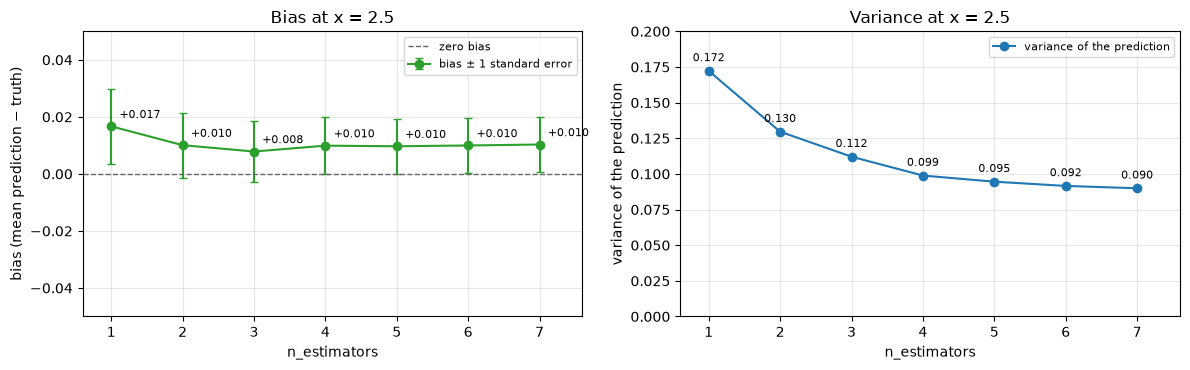

In [21]:
sizes_11 = np.arange(1, N_TREES + 1)
forest_at_point = np.cumsum(tree_at_point, axis=1) / sizes_11      # [training set, n]: the n-tree forest's prediction
bias_by_n = forest_at_point.mean(axis=0) - true_pattern(X_POINT)
bias_error = forest_at_point.std(axis=0) / np.sqrt(N_REPEATS)       # standard error of each bias
variance_by_n = forest_at_point.var(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].errorbar(sizes_11, bias_by_n, yerr=bias_error, fmt="o-", color="tab:green", capsize=3,
                 label="bias ± 1 standard error")
axes[0].axhline(0, color="0.4", lw=1, ls="--", label="zero bias")
axes[0].set(ylim=(-0.05, 0.05), ylabel="bias (mean prediction − truth)", title=f"Bias at x = {X_POINT}")
axes[1].plot(sizes_11, variance_by_n, "o-", color="tab:blue", label="variance of the prediction")
axes[1].set(ylim=(0, 0.2), ylabel="variance of the prediction", title=f"Variance at x = {X_POINT}")
for n, b, v in zip(sizes_11, bias_by_n, variance_by_n):
    axes[0].annotate(f"{b:+.3f}", (n, b), textcoords="offset points", xytext=(6, 6), fontsize=8)
    axes[1].annotate(f"{v:.3f}", (n, v), textcoords="offset points", xytext=(0, 7), fontsize=8, ha="center")
for ax in axes:
    ax.set(xlabel="n_estimators", xticks=sizes_11, xlim=(0.6, N_TREES + 0.6))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

> **How to read this**
> * **The estimators are not identical in the printout.** Their variances range from 0.151 (estimator 4) to
>   0.172 (estimator 1), and the 21 pairwise correlations at $x = 2.5$ from 0.404 to 0.507. These are estimates
>   from 1 000 training sets; one standard error of a correlation that size is about 0.025, so a spread of
>   ±0.05 around the mean (0.466) is what measurement noise alone produces.
> * **The formula as written survives — and with the right $\rho$ it is exact.** With $\sigma^2$ = mean of the
>   printed variances and $\rho$ = plain mean of the printed correlations, $\rho\sigma^2 + (1-\rho)\sigma^2/n$ lands
>   within 0.1 % of the actual variance for every size from 2 to 7 trees (worst case $n = 4$: 0.09878 vs 0.09884).
>   With $\rho$ = mean covariance ÷ mean variance (0.4653 instead of 0.4648 at $n = 4$) it equals the actual variance
>   exactly, at every $n$. The reason: the pair-by-pair sum weights each pair's $\rho_{ij}$ by $\sigma_i\sigma_j$, the two
>   trees' spreads, while a plain mean weights every pair equally; the covariance-based $\rho$ is exactly the
>   weighted one.
> * **The all-pairs version is not an approximation at all**: it equals the LHS to every printed digit for every
>   $n$, because it is just the variance of a sum written out pair by pair.
> * **Bias against `n_estimators` (11.8) is flat; the variance falls.** At $x = 2.5$ the bias is about +0.01 for
>   every forest size (+0.017 for one tree, +0.008 to +0.010 after), each within about one standard error
>   (≈ 0.01) of zero: averaging does not move the bias. The variance drops from 0.172 to 0.090, steeply up to about
>   4 trees and slowly after.
> * **The LHS falls fast and then flattens:** 0.172 (1 tree), 0.130, 0.112, 0.099, 0.095, 0.092, 0.090 (7 trees).
>   In the RHS that is the second term, $(1-\rho)\sigma^2/n$, shrinking (0.042 at 2 trees, 0.013 at 7), while the
>   first term $\rho\sigma^2$ stays between 0.077 and 0.087 — the floor no number of trees can remove.
> * **The plain mean is this close because the trees' variances are nearly equal** — every tree is grown by the
>   same random procedure from the same training set. Members of different kinds (as in voting) can have very
>   different variances, and then the plain mean can be far off; with $\rho$ = mean covariance ÷ mean variance the
>   compact formula stays exact for any ensemble.

<a id="feature-subsampling"></a>
### 11.9 · Feature subsampling: does it lower $\rho$, and what does it do to the bias?

A random forest differs from bagging in one way: each split chooses among a random subset of `max_features`
features instead of all of them. The claim in the README (sections 3 and 8) is that this makes the trees' errors
less correlated, so the floor $\rho\sigma^2$ drops, while each tree gets a little worse. The data above has a single
feature, so `max_features` has nothing to choose from: every forest in 11.1–11.8 is plain bagging. Here the source
gets 20 features; everything else stays as above (the pattern, the noise, 60 rows per training set, 1 000 training
sets, 7 trees), and two forests are grown on every training set:

* **bagging**: `max_features=1.0`, all 20 features at every split (scikit-learn's default for regression);
* **random forest**: `max_features="sqrt"`, 4 of the 20 at every split.

Two versions of the 20 features:

* **sparse signal**: $x_1$ is the input of section 1 and the other 19 features are pure noise, all uniform on
  $[0, 5]$. The best possible prediction is $E[y \mid \mathbf{x}] = f(x_1)$.
* **redundant copies**: a hidden $z$, uniform on $[0, 5]$, sets $y = f(z) + \varepsilon$, and every feature is a
  noisy copy of it: $x_1 = z + \mathcal{N}(0, 0.3^2)$ and $x_2, \dots, x_{20} = z + \mathcal{N}(0, 0.6^2)$ (the design
  of the random-forest lab's good-fit data). The best possible prediction $E[y \mid \mathbf{x}]$ averages $f(z)$ over
  the values of $z$ that the 20 copies make plausible.

**What is measured.** $T_b(\mathbf{x})$ is tree $b$'s prediction at $\mathbf{x}$, $F(\mathbf{x})$ the 7-tree
forest's (their average), and $D$ the training set. At each of 100 probe points drawn from the same source,
variances and covariances are taken across the 1 000 training sets, as in 11.1–11.7; a bar means the average of
that over the probe points:

$$\sigma_i^2 = \overline{\text{Var}_D\big(T_i(\mathbf{x})\big)}, \qquad
\sigma^2 = \frac{1}{n}\sum_{i=1}^{n}\sigma_i^2, \qquad
\rho = \frac{1}{\sigma^2}\cdot\frac{1}{n(n-1)}\sum_{i=1}^{n}\sum_{\substack{j=1\\ j\neq i}}^{n}\overline{\text{Cov}_D\big(T_i(\mathbf{x}), T_j(\mathbf{x})\big)}.$$

This is the README's $\rho$ (section 3), pooled over the probe points. With it the average variance of an
$n$-tree forest is exactly $\overline{\text{Var}_D(F)} = \rho\sigma^2 + (1-\rho)\sigma^2/n$, and because the trees
of a forest are interchangeable, $\sigma^2$ and $\rho$ do not depend on $n$: the same two numbers give the variance
of a 100-tree forest. The bias does not depend on $n$ either (the forest's average prediction is one tree's average
prediction). It is measured as

$$\text{bias}^2 = \overline{\big(\bar F(\mathbf{x}) - E[y \mid \mathbf{x}]\big)^2} \;-\; \frac{\overline{\text{Var}_D\big(F(\mathbf{x})\big)}}{1000},$$

where $\bar F(\mathbf{x})$ is the forest's prediction averaged over the 1 000 training sets; the second term removes
the part of the gap that comes only from averaging 1 000 training sets instead of infinitely many.

**Why 100 points and not one.** At a single input the measured $\rho$ swings a lot from point to point (each
printout below gives its range), so one point can point the opposite way from the average.

In [22]:
P_FEATURES = 20
COPY_SD = np.r_[0.3, np.full(P_FEATURES - 1, 0.6)]     # redundant copies: noise on each copy of the hidden z
N_PROBE = 100                                           # probe points the measurements are averaged over
MAX_FEATURES = {"bagging": 1.0, "random forest": "sqrt"}   # sqrt(20) -> 4 candidate features per split
z_grid_11 = np.linspace(X_MIN, X_MAX, 4001)


def draw_sparse(rng, n=N_POINTS):
    X = rng.uniform(X_MIN, X_MAX, (n, P_FEATURES))      # x1 carries the pattern, x2..x20 are pure noise
    return X, true_pattern(X[:, 0]) + rng.normal(0, NOISE_SD, n)


def draw_redundant(rng, n=N_POINTS):
    z = rng.uniform(X_MIN, X_MAX, n)                    # hidden; every feature is a noisy copy of it
    X = z[:, None] + rng.normal(0, 1, (n, P_FEATURES)) * COPY_SD
    return X, true_pattern(z) + rng.normal(0, NOISE_SD, n)


def best_prediction_redundant(X):
    """E[y | x]: average f(z) over z, weighted by how well each z explains the 20 noisy copies."""
    log_lik = -0.5 * (((X[:, None, :] - z_grid_11[None, :, None]) / COPY_SD) ** 2).sum(axis=2)
    weights = np.exp(log_lik - log_lik.max(axis=1, keepdims=True))
    return (weights * true_pattern(z_grid_11)).sum(axis=1) / weights.sum(axis=1)


DATASETS = {
    "sparse signal": (draw_sparse, lambda X: true_pattern(X[:, 0])),
    "redundant copies": (draw_redundant, best_prediction_redundant),
}
rng_probe = np.random.default_rng(SEED + 3)
probe_x, probe_truth = {}, {}
for name, (draw, best_prediction) in DATASETS.items():
    probe_x[name] = draw(rng_probe, N_PROBE)[0]
    probe_truth[name] = best_prediction(probe_x[name])

tree_preds_11 = {}   # (dataset, forest) -> predictions [training set, tree, probe point]
root_on_x1 = {}      # (dataset, forest) -> share of trees whose first split uses x1
for name, (draw, _) in DATASETS.items():
    rng_sets = np.random.default_rng(SEED + 2)
    for forest_name in MAX_FEATURES:
        tree_preds_11[name, forest_name] = np.empty((N_REPEATS, N_TREES, N_PROBE))
        root_on_x1[name, forest_name] = 0
    for r in range(N_REPEATS):
        X_r, y_r = draw(rng_sets)                       # both forests are grown on the same training set
        for forest_name, max_features in MAX_FEATURES.items():
            forest_r = RandomForestRegressor(n_estimators=N_TREES, max_features=max_features, random_state=r)
            forest_r.fit(X_r, y_r)
            tree_preds_11[name, forest_name][r] = [tree.predict(probe_x[name]) for tree in forest_r.estimators_]
            root_on_x1[name, forest_name] += sum(tree.tree_.feature[0] == 0 for tree in forest_r.estimators_)


def check_subsampling(name, forest_name):
    """Per-tree variances, the rho_ij table, the formula term by term, and the bias^2, pooled over the probe points."""
    preds = tree_preds_11[name, forest_name]
    dev = preds - preds.mean(axis=0)
    cov = np.einsum("rip,rjp->ijp", dev, dev) / N_REPEATS      # Cov_D(T_i(x), T_j(x)) at every probe point
    cov_pooled = cov.mean(axis=2)                             # averaged over the probe points
    variances = np.diag(cov_pooled)                           # sigma_i^2, one per tree
    off_diagonal = ~np.eye(N_TREES, dtype=bool)
    sigma2 = variances.mean()
    rho = cov_pooled[off_diagonal].mean() / sigma2
    rho_table = cov_pooled / np.sqrt(np.outer(variances, variances))
    rho_at_point = cov[off_diagonal].mean(axis=0) / np.diagonal(cov).mean(axis=1)
    forest = preds.mean(axis=1)                               # the 7-tree forest, [training set, probe point]
    lhs = forest.var(axis=0).mean()
    bias2 = np.mean((forest.mean(axis=0) - probe_truth[name]) ** 2) - lhs / N_REPEATS

    print(f"{name}, {forest_name} (max_features={MAX_FEATURES[forest_name]!r}): {N_TREES} trees, "
          f"{N_REPEATS} training sets, averaged over {N_PROBE} probe points")
    print(f"first split on x1 in {root_on_x1[name, forest_name] / (N_REPEATS * N_TREES):.1%} of the "
          f"{N_REPEATS * N_TREES} trees\n")
    for i, variance in enumerate(variances, start=1):
        print(f"estimator {i}, variance = {variance:.5f}")
    print("\npairwise correlation rho_ij:")
    print("        " + "".join(f"{'est ' + str(j):>8}" for j in range(1, N_TREES + 1)))
    for i in range(N_TREES):
        print(f"est {i + 1:<4}" + "".join(f"{rho_table[i, j]:8.3f}" for j in range(N_TREES)))
    print(f"rho at single probe points: min {rho_at_point.min():.3f}, median {np.median(rho_at_point):.3f}, "
          f"max {rho_at_point.max():.3f}")

    term_1, term_2 = rho * sigma2, (1 - rho) * sigma2 / N_TREES
    print(f"\nLHS  actual variance of the {N_TREES}-tree forest's prediction: {lhs:.5f}")
    print(f"RHS  rho = mean covariance / mean variance = {rho * sigma2:.5f} / {sigma2:.5f} = {rho:.4f}:")
    print(f"     {rho:.4f} x {sigma2:.5f} + (1 - {rho:.4f}) x {sigma2:.5f} / {N_TREES}"
          f" = {term_1:.5f} + {term_2:.5f} = {term_1 + term_2:.5f}   ({(term_1 + term_2) / lhs - 1:+.4%} vs LHS)")
    var_100 = rho * sigma2 + (1 - rho) * sigma2 / 100
    print(f"     the same two numbers with 100 trees: {term_1:.5f} + {(1 - rho) * sigma2 / 100:.5f} = {var_100:.5f}")
    print(f"bias^2 = {bias2:.5f}")
    return {"sigma2": sigma2, "rho": rho, "floor": term_1, "var_7": lhs, "var_100": var_100, "bias2": bias2}


subsampling_results = {}
print(f"{N_REPEATS} training sets of {N_POINTS} rows and {P_FEATURES} features; "
      f"{N_TREES}-tree forests; {N_PROBE} probe points per dataset")

1000 training sets of 60 rows and 20 features; 7-tree forests; 100 probe points per dataset


### 11.10 · Sparse signal, bagging (all 20 features at every split)

In [23]:
subsampling_results["sparse signal", "bagging"] = check_subsampling("sparse signal", "bagging")

sparse signal, bagging (max_features=1.0): 7 trees, 1000 training sets, averaged over 100 probe points
first split on x1 in 96.5% of the 7000 trees

estimator 1, variance = 0.38378
estimator 2, variance = 0.39026
estimator 3, variance = 0.39946
estimator 4, variance = 0.39703
estimator 5, variance = 0.39102
estimator 6, variance = 0.38654
estimator 7, variance = 0.39276

pairwise correlation rho_ij:
           est 1   est 2   est 3   est 4   est 5   est 6   est 7
est 1      1.000   0.150   0.144   0.148   0.150   0.161   0.157
est 2      0.150   1.000   0.160   0.138   0.158   0.152   0.158
est 3      0.144   0.160   1.000   0.147   0.158   0.154   0.161
est 4      0.148   0.138   0.147   1.000   0.152   0.146   0.149
est 5      0.150   0.158   0.158   0.152   1.000   0.152   0.152
est 6      0.161   0.152   0.154   0.146   0.152   1.000   0.146
est 7      0.157   0.158   0.161   0.149   0.152   0.146   1.000
rho at single probe points: min 0.114, median 0.142, max 0.231

LHS  actual v

### 11.11 · Sparse signal, random forest (4 of 20 at every split)

In [24]:
subsampling_results["sparse signal", "random forest"] = check_subsampling("sparse signal", "random forest")

sparse signal, random forest (max_features='sqrt'): 7 trees, 1000 training sets, averaged over 100 probe points
first split on x1 in 20.3% of the 7000 trees

estimator 1, variance = 0.70753
estimator 2, variance = 0.70827
estimator 3, variance = 0.69873
estimator 4, variance = 0.69111
estimator 5, variance = 0.69316
estimator 6, variance = 0.70310
estimator 7, variance = 0.69152

pairwise correlation rho_ij:
           est 1   est 2   est 3   est 4   est 5   est 6   est 7
est 1      1.000   0.052   0.055   0.052   0.052   0.057   0.051
est 2      0.052   1.000   0.047   0.046   0.052   0.054   0.050
est 3      0.055   0.047   1.000   0.045   0.049   0.043   0.043
est 4      0.052   0.046   0.045   1.000   0.046   0.046   0.041
est 5      0.052   0.052   0.049   0.046   1.000   0.047   0.039
est 6      0.057   0.054   0.043   0.046   0.047   1.000   0.041
est 7      0.051   0.050   0.043   0.041   0.039   0.041   1.000
rho at single probe points: min 0.029, median 0.049, max 0.070

LHS 

### 11.12 · Redundant copies, bagging (all 20 features at every split)

In [25]:
subsampling_results["redundant copies", "bagging"] = check_subsampling("redundant copies", "bagging")

redundant copies, bagging (max_features=1.0): 7 trees, 1000 training sets, averaged over 100 probe points
first split on x1 in 22.6% of the 7000 trees

estimator 1, variance = 0.47014
estimator 2, variance = 0.46865
estimator 3, variance = 0.46551
estimator 4, variance = 0.46464
estimator 5, variance = 0.45761
estimator 6, variance = 0.46326
estimator 7, variance = 0.46309

pairwise correlation rho_ij:
           est 1   est 2   est 3   est 4   est 5   est 6   est 7
est 1      1.000   0.120   0.126   0.120   0.131   0.121   0.135
est 2      0.120   1.000   0.133   0.119   0.123   0.136   0.126
est 3      0.126   0.133   1.000   0.123   0.126   0.133   0.126
est 4      0.120   0.119   0.123   1.000   0.129   0.124   0.117
est 5      0.131   0.123   0.126   0.129   1.000   0.133   0.128
est 6      0.121   0.136   0.133   0.124   0.133   1.000   0.130
est 7      0.135   0.126   0.126   0.117   0.128   0.130   1.000
rho at single probe points: min 0.089, median 0.128, max 0.185

LHS  actua

### 11.13 · Redundant copies, random forest (4 of 20 at every split)

In [26]:
subsampling_results["redundant copies", "random forest"] = check_subsampling("redundant copies", "random forest")

redundant copies, random forest (max_features='sqrt'): 7 trees, 1000 training sets, averaged over 100 probe points
first split on x1 in 12.7% of the 7000 trees

estimator 1, variance = 0.45710
estimator 2, variance = 0.45663
estimator 3, variance = 0.44600
estimator 4, variance = 0.45010
estimator 5, variance = 0.44941
estimator 6, variance = 0.45163
estimator 7, variance = 0.45042

pairwise correlation rho_ij:
           est 1   est 2   est 3   est 4   est 5   est 6   est 7
est 1      1.000   0.072   0.071   0.072   0.072   0.072   0.073
est 2      0.072   1.000   0.068   0.065   0.068   0.079   0.059
est 3      0.071   0.068   1.000   0.071   0.077   0.064   0.071
est 4      0.072   0.065   0.071   1.000   0.071   0.069   0.069
est 5      0.072   0.068   0.077   0.071   1.000   0.067   0.070
est 6      0.072   0.079   0.064   0.069   0.067   1.000   0.069
est 7      0.073   0.059   0.071   0.069   0.070   0.069   1.000
rho at single probe points: min 0.028, median 0.071, max 0.151

L

### 11.14 · Side by side

dataset           forest          sigma^2     rho   rho*s2  Var, 7 trees  Var, 100 trees   bias^2  bias^2+Var(100)
sparse signal     bagging          0.3915   0.152   0.0596        0.1070          0.0629   0.0951           0.1580
sparse signal     random forest    0.6991   0.048   0.0335        0.1286          0.0402   0.2741           0.3143
redundant copies  bagging          0.4647   0.127   0.0588        0.1168          0.0629   0.1272           0.1901
redundant copies  random forest    0.4516   0.070   0.0315        0.0916          0.0357   0.1098           0.1455


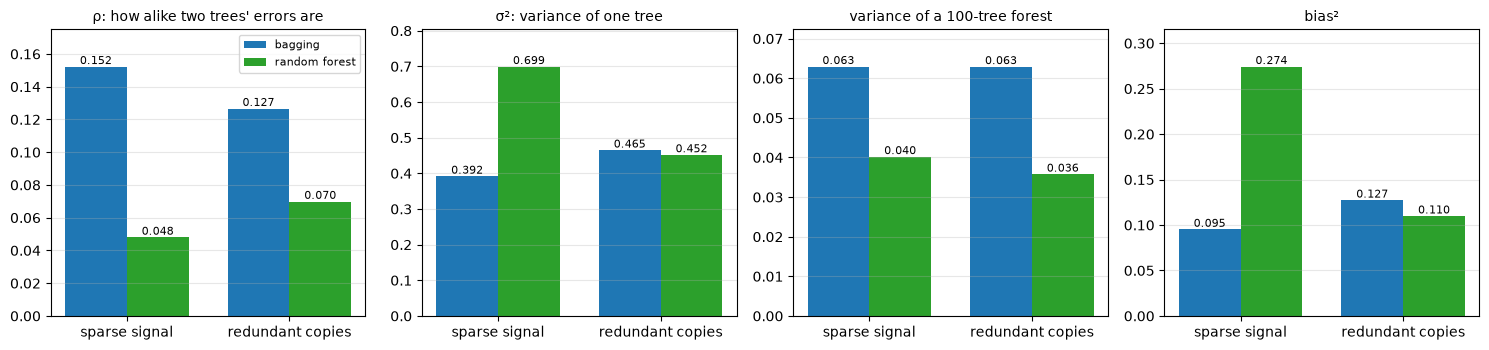

In [27]:
print(f"{'dataset':17s} {'forest':14s} {'sigma^2':>8s} {'rho':>7s} {'rho*s2':>8s} "
      f"{'Var, 7 trees':>13s} {'Var, 100 trees':>15s} {'bias^2':>8s} {'bias^2+Var(100)':>16s}")
for (name, forest_name), res in subsampling_results.items():
    print(f"{name:17s} {forest_name:14s} {res['sigma2']:8.4f} {res['rho']:7.3f} {res['floor']:8.4f} "
          f"{res['var_7']:13.4f} {res['var_100']:15.4f} {res['bias2']:8.4f} {res['bias2'] + res['var_100']:16.4f}")

panels = [("rho", "ρ: how alike two trees' errors are"), ("sigma2", "σ²: variance of one tree"),
          ("var_100", "variance of a 100-tree forest"), ("bias2", "bias²")]
names = list(DATASETS)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (key, title) in zip(axes, panels):
    for k, (forest_name, colour) in enumerate([("bagging", "tab:blue"), ("random forest", "tab:green")]):
        values = [subsampling_results[name, forest_name][key] for name in names]
        bars = ax.bar(np.arange(2) + (k - 0.5) * 0.38, values, width=0.38, color=colour, label=forest_name)
        ax.bar_label(bars, fmt="%.3f", fontsize=8)
    ax.set_xticks(np.arange(2), names)
    ax.set_title(title, fontsize=10)
    ax.margins(y=0.15)
    ax.grid(alpha=0.3, axis="y")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * **Bagging's $\rho$ is already far lower here than in 11.1–11.7:** 0.152 (sparse) and 0.127 (redundant), against
>   0.466 on the one-feature data. A fully grown tree predicts a point from the few rows in its leaf, and with 20
>   features which rows end up in that leaf changes a lot from one bootstrap sample to the next.
> * **Feature subsampling lowers $\rho$ further in both datasets:** 0.152 → 0.048 (sparse) and 0.127 → 0.070
>   (redundant), so the floor $\rho\sigma^2$ falls from 0.060 to 0.034 and from 0.059 to 0.032. On the sparse data
>   bagging asks its first question about $x_1$ in 96.5 % of the trees and the random forest in 20.3 %.
> * **What it does to one tree depends on the data.** Redundant copies: $\sigma^2$ barely moves (0.465 → 0.452),
>   because every set of 4 candidates contains copies of $z$. Sparse signal: $\sigma^2$ almost doubles
>   (0.392 → 0.699), because $x_1$ is not among the 4 candidates at 80 % of the splits ($16/20$), so most splits cut
>   on noise.
> * **So whether the forest's variance falls depends on its size.** With 100 trees, where the floor dominates, the
>   random forest has the lower variance on both datasets: 0.063 → 0.040 (sparse) and 0.063 → 0.036 (redundant).
>   With 7 trees the second term $(1-\rho)\sigma^2/n$ still matters, and on the sparse data the doubled $\sigma^2$
>   wins: 0.107 → 0.129. On the redundant data it falls even with 7 trees (0.117 → 0.092).
> * **The bias moves in opposite directions.** Redundant copies: bias² falls a little, 0.127 → 0.110; the random
>   forest's trees split on more of the copies, whose noise partly cancels (the random-forest lab's Lab 6 saw the
>   same on its good-fit data, 0.113 → 0.083). Sparse signal: bias² almost triples, 0.095 → 0.274; splits on noise
>   flatten the pattern of $x_1$ in every tree alike, and averaging cannot remove a shared error.
> * **Net, with 100 trees (bias² + variance):** redundant copies 0.190 → 0.146, the random forest wins; sparse signal
>   0.158 → 0.314, it loses by a factor of two. Subsampling features buys a lower $\rho$ with weaker trees: worth it
>   when many features carry the signal, not when few do (then a larger `max_features`, chosen by out-of-bag score as
>   in the random-forest lab's Lab 11).
> * **One point is not enough.** At single probe points $\rho$ ranges from 0.089 to 0.185 for bagging on the redundant
>   data and from 0.028 to 0.151 for the random forest: the ranges overlap, so a single point could show the opposite.
> * **This $\rho$ is not the random-forest lab's.** Lab 4 there reports 0.404 → 0.297 for the similarity of two trees'
>   errors over the test points of one forest; those errors include the bias and noise every tree shares, so that
>   number is much larger. It moves the same way.